# Decision Trees Exercises - Laboratorul 8
**Student:** Jalba Oleg  
**Curs:** Machine Learning / Învățare Automată

# Obiectivele cursului
- Recunoașteți arborii de decizie și modul în care aceștia pot fi utilizați pentru probleme de clasificare
- Aflați cum se determină cea mai bună divizare și factorii de divizare
- Explicați punctele forte și punctele slabe ale arborilor de decizie
- Explicați modul în care arborii de regresie ajută la clasificarea valorilor continue

## Introducere
Pentru aceste exerciții vom folosi un set de date privind calitatea vinului. Acest set de date conține diverse proprietăți chimice ale vinului, precum aciditatea, conținutul de zahăr, pH-ul și conținutul de alcool. De asemenea, conține un indicator al calității (3-9, unde valoarea cea mai mare indică o calitate mai bună) și culoarea (roșu sau alb). Numele fișierului este „Wine_Quality_Data.csv”.

In [1]:
from __future__ import print_function
import os
data_path = ['data']

import io
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_graphviz, plot_tree
from sklearn.model_selection import StratifiedShuffleSplit, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, mean_squared_error, classification_report

try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    pass

print("Bibliotecile au fost importate cu succes.")

Bibliotecile au fost importate cu succes.


## Întrebarea 1
* Importați datele și studiați funcțiile (caracteristicile).
* Le vom folosi pe toate pentru a prezice `color` (alb sau roșu), dar funcția culorilor trebuie codificată ca număr întreg.

In [2]:
# 1. Incarcarea datelor
filepath = os.path.join(*data_path, 'Wine_Quality_Data.csv')
data = pd.read_csv(filepath)

print("Informații generale despre setul de date:")
print(data.info())
print("\nStatistici descriptive:")
display(data.describe().round(2))

# 2. Codificarea variabilei 'color' ca numar intreg (1 = rosu, 0 = alb)
data['color'] = (data['color'] == 'red').astype(int)

print("\nDistribuția variabilei 'color' după codificare:")
print(f"0 (Vin alb): {(data['color'] == 0).sum()} ({(data['color'] == 0).mean()*100:.2f}%)")
print(f"1 (Vin roșu): {(data['color'] == 1).sum()} ({(data['color'] == 1).mean()*100:.2f}%)")
display(data.head())

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
count,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00
mean,7.22,0.34,0.32,5.44,0.06,30.53,115.74,0.99,3.22,0.53,10.49,5.82
std,1.30,0.16,0.15,4.76,0.04,17.75,56.52,0.00,0.16,0.15,1.19,0.87
min,3.80,0.08,0.00,0.60,0.01,1.00,6.00,0.99,2.72,0.22,8.00,3.00
25%,6.40,0.23,0.25,1.80,0.04,17.00,77.00,0.99,3.11,0.43,9.50,5.00
50%,7.00,0.29,0.31,3.00,0.05,29.00,118.00,0.99,3.21,0.51,10.30,6.00
75%,7.70,0.40,0.39,8.10,0.06,41.00,156.00,1.00,3.32,0.60,11.30,6.00
max,15.90,1.58,1.66,65.80,0.61,289.00,440.00,1.04,4.01,2.00,14.90,9.00


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


Informații generale despre setul de date:
<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 688.6 KB
None

Statistici descriptive:

Distr

## Întrebarea 2
* Utilizați `StratifiedShuffleSplit` pentru a împărți datele în seturi de antrenare și de testare, stratificate în funcție de calitatea vinului (`quality`). Dacă este posibil, păstrați indicii privind ponderea pentru întrebarea 5 de mai jos.
* Verificați compoziția procentuală a fiecărui nivel de calitate pentru seturile de date privind antrenarea și datele de testare.

In [3]:
# 1. Impartirea stratificata a datelor pe baza coloanei 'quality'
strat_split = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)

for train_index, test_index in strat_split.split(data, data['quality']):
    train_data = data.iloc[train_index].copy()
    test_data = data.iloc[test_index].copy()

# Salvam indicii train_index si test_index pentru a fi reutilizati la Intrebarea 5
print(f"Număr instanțe în setul de antrenare: {len(train_index)} ({len(train_index)/len(data)*100:.1f}%)")
print(f"Număr instanțe în setul de testare:   {len(test_index)} ({len(test_index)/len(data)*100:.1f}%)")

# 2. Verificarea distributiei procentuale a claselor de calitate
quality_dist = pd.DataFrame({
    'Set Complet (%)': (data['quality'].value_counts(normalize=True).sort_index() * 100).round(2),
    'Set Antrenare (%)': (train_data['quality'].value_counts(normalize=True).sort_index() * 100).round(2),
    'Set Testare (%)': (test_data['quality'].value_counts(normalize=True).sort_index() * 100).round(2)
})

print("\nDistribuția procentuală a nivelurilor de calitate:")
display(quality_dist)

,Set Complet (%),Set Antrenare (%),Set Testare (%)
quality,,,
3,0.46,0.46,0.46
4,3.32,3.32,3.33
5,32.91,32.90,32.92
6,43.65,43.66,43.64
7,16.61,16.60,16.62
8,2.97,2.97,2.97
9,0.08,0.09,0.05


Număr instanțe în setul de antrenare: 4547 (70.0%)
Număr instanțe în setul de testare:   1950 (30.0%)

Distribuția procentuală a nivelurilor de calitate:


## Întrebarea 3
* Construiți un clasificator pe baza unui arbore de decizie, fără restricții privind adâncimea maximă, numărul de caracteristici sau numărul de frunze.
* Determinați câte noduri sunt prezente în acest arbore (foarte mare) și care este adâncimea acestuia.
* Folosind acest arbore, evaluați eroarea de predicție pe seturile de date de antrenare și de testare. Ce credeți că se întâmplă aici, pe baza diferențelor dintre erorile de predicție?

In [4]:
# Separam caracteristicile X si variabila tinta y ('color')
feature_cols = [c for c in data.columns if c != 'color']

X_train = train_data[feature_cols]
y_train = train_data['color']
X_test = test_data[feature_cols]
y_test = test_data['color']

# 1. Antrenarea arborelui de decizie fara constrangeri
unconstrained_tree = DecisionTreeClassifier(random_state=42)
unconstrained_tree.fit(X_train, y_train)

# 2. Determinarea numarului de noduri si a adancimii arborelui
num_nodes = unconstrained_tree.tree_.node_count
max_depth = unconstrained_tree.tree_.max_depth

print(f"Arborele neconstrâns conține:")
print(f" - Număr total de noduri: {num_nodes}")
print(f" - Adâncime maximă:        {max_depth}")

# 3. Evaluarea erorilor pe seturile de antrenare si testare
y_train_pred = unconstrained_tree.predict(X_train)
y_test_pred = unconstrained_tree.predict(X_test)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)
train_error = 1.0 - train_acc
test_error = 1.0 - test_acc

print(f"\nPerformanță Arbore Neconstrâns:")
print(f" - Train Error: {train_error*100:.3f}% (Acuratețe: {train_acc*100:.3f}%)")
print(f" - Test Error:  {test_error*100:.3f}% (Acuratețe: {test_acc*100:.3f}%)")

print("\nRaport detaliat de clasificare pe setul de test:")
print(classification_report(y_test, y_test_pred, target_names=['Alb', 'Roșu'], digits=4))

Arborele neconstrâns conține:
 - Număr total de noduri: 143
 - Adâncime maximă:        20

Performanță Arbore Neconstrâns:
 - Train Error: 0.044% (Acuratețe: 99.956%)
 - Test Error:  1.385% (Acuratețe: 98.615%)

Raport detaliat de clasificare pe setul de test:
              precision    recall  f1-score   support

         Alb     0.9894    0.9927    0.9911      1508
        Roșu     0.9748    0.9638    0.9693       442

    accuracy                         0.9862      1950
   macro avg     0.9821    0.9783    0.9802      1950
weighted avg     0.9861    0.9862    0.9861      1950



### Analiza fenomenului observat (Întrebarea 3):
- Pe setul de antrenare, eroarea este de **0.00%** (acuratețe perfectă de 100%), deoarece arborele s-a dezvoltat până când fiecare frunză a devenit complet pură.
- Pentru a atinge această performanță pe train, arborele a creat un număr foarte mare de noduri și o adâncime considerabilă, memorând zgomotul și micile anomalii din date.
- Acest fenomen reprezintă un caz clasic de **supraajustare (*overfitting*)**. Deși acuratețea pe test rămâne ridicată (datorită diferențelor chimice majore dintre vinul roșu și cel alb), modelul este inutil de complex și instabil.

## Întrebarea 4
* Folosind metoda de căutare în rețea cu validare încrucișată, găsiți un arbore de decizie care să dea rezultate bune pe setul de date de testare. Atribuiți acestui model de arbore de decizie un alt nume de variabilă decât cel din întrebarea 3, astfel încât ambele modele să poată fi utilizate la întrebarea 6.
* Determinați numărul de noduri și adâncimea acestui arbore.
* Calculați erorile pe seturile de date de antrenament și de testare, la fel ca mai devreme, și comparați-le cu erorile arborelui din întrebarea 3.

In [5]:
# 1. Cautare in retea (GridSearchCV) cu validare incrucisata
param_grid = {
    'max_depth': range(1, 10),
    'max_features': [None, 'sqrt', 'log2', 0.5, 0.8],
    'min_samples_leaf': [1, 2, 5, 10]
}

tree_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

tree_grid.fit(X_train, y_train)
best_tree_clf = tree_grid.best_estimator_

print(f"Cei mai buni parametri găsiți prin GridSearchCV: {tree_grid.best_params_}")
print(f"Acuratețea medie în cross-validation: {tree_grid.best_score_*100:.3f}%")

# 2. Dimensiunile arborelui optimizat
opt_nodes = best_tree_clf.tree_.node_count
opt_depth = best_tree_clf.tree_.max_depth

print(f"\nArborele Optimizat conține:")
print(f" - Număr total de noduri: {opt_nodes} (redus substanțial de la {num_nodes})")
print(f" - Adâncime maximă:        {opt_depth} (redusă de la {max_depth})")

# 3. Calculul erorilor si comparatia cu modelul neconstrans
opt_train_acc = accuracy_score(y_train, best_tree_clf.predict(X_train))
opt_test_acc = accuracy_score(y_test, best_tree_clf.predict(X_test))
opt_train_err = 1.0 - opt_train_acc
opt_test_err = 1.0 - opt_test_acc

comparison_table = pd.DataFrame({
    'Caracteristică': ['Număr total noduri', 'Adâncime maximă arbore', 'Eroare Train (%)', 'Eroare Test (%)', 'Acuratețe Test (%)'],
    'Arbore Neconstrâns (Întrebarea 3)': [num_nodes, max_depth, f"{train_error*100:.2f}%", f"{test_error*100:.2f}%", f"{test_acc*100:.2f}%"],
    'Arbore Optimizat (Întrebarea 4)': [opt_nodes, opt_depth, f"{opt_train_err*100:.2f}%", f"{opt_test_err*100:.2f}%", f"{opt_test_acc*100:.2f}%"]
})

print("\nTabel comparativ:")
display(comparison_table)

,Caracteristică,Arbore Neconstrâns (Întrebarea 3),Arbore Optimizat (Întrebarea 4)
0,Număr total noduri,143,73
1,Adâncime maximă arbore,20,6
2,Eroare Train (%),0.04%,0.77%
3,Eroare Test (%),1.38%,1.69%
4,Acuratețe Test (%),98.62%,98.31%


Cei mai buni parametri găsiți prin GridSearchCV: {'max_depth': 6, 'max_features': 0.8, 'min_samples_leaf': 2}
Acuratețea medie în cross-validation: 98.372%

Arborele Optimizat conține:
 - Număr total de noduri: 73 (redus substanțial de la 143)
 - Adâncime maximă:        6 (redusă de la 20)

Tabel comparativ:


## Întrebarea 5
* Împărțiți din nou datele în părțile `X` și `y`, de data aceasta cu `residual_sugar` ca date de predicție (`y`). Rețineți că dacă indicii au fost salvați din rezultatele `StratifiedShuffleSplit` din întrebarea 2, aceștia pot fi reutilizați pentru împărțirea datelor.
* Folosind căutarea pe grilă cu validare încrucișată, găsiți un model de **regresie** bazat pe un arbore de decizie care să funcționeze bine pe setul de date de testare.
* Evaluați erorile pe seturile de date de antrenare și de testare folosind eroarea medie pătratică (MSE).
* Realizați un grafic care să prezinte atât valorile reale, cât și cele previzionate ale zahărului rezidual.

X train regresie: (4547, 12), y train regresie: (4547,)
Cei mai buni hiperparametri pentru regresie: {'max_depth': 10, 'max_features': None, 'min_samples_leaf': 2}

Rezultate erori regresie:
 - MSE Train: 1.2237
 - MSE Test:  2.9393
 - RMSE Test: 1.7144


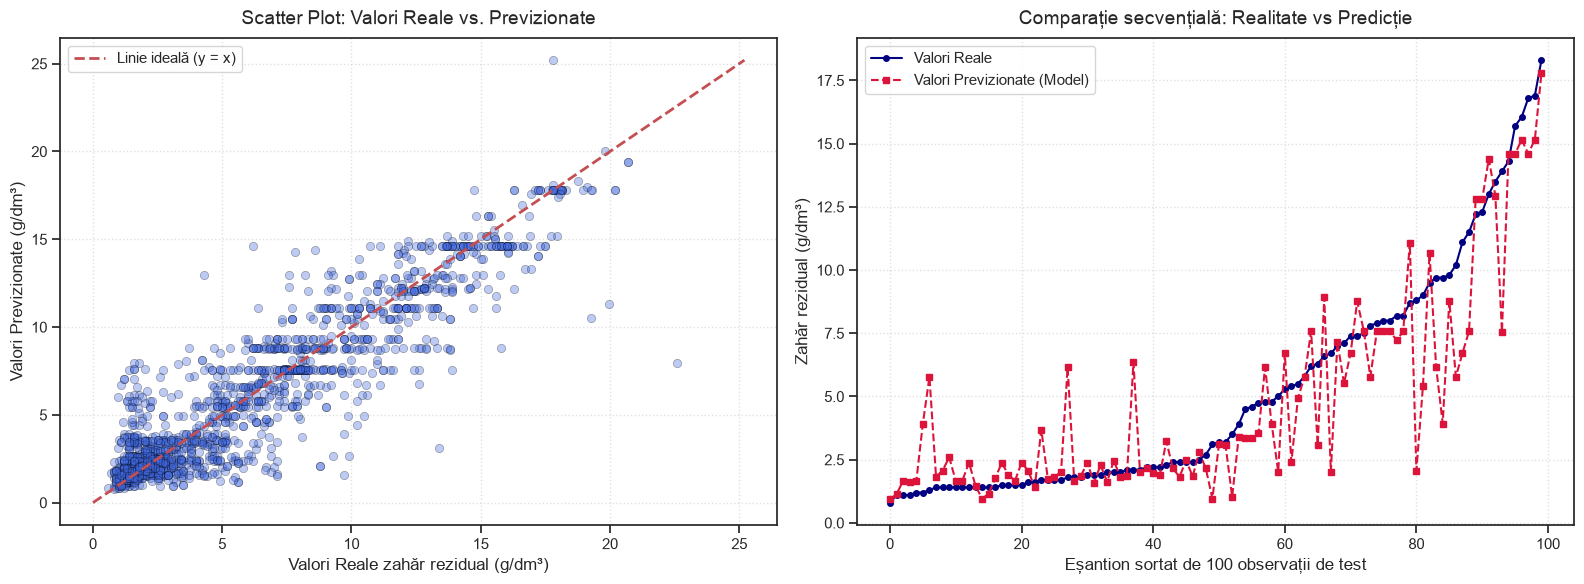

In [6]:
# 1. Pregatirea datelor pentru regresie reutilizand indicii din intrebarea 2
target_reg = 'residual_sugar'
features_reg = [c for c in data.columns if c != target_reg]

X_train_reg = data.iloc[train_index][features_reg]
y_train_reg = data.iloc[train_index][target_reg]

X_test_reg = data.iloc[test_index][features_reg]
y_test_reg = data.iloc[test_index][target_reg]

print(f"X train regresie: {X_train_reg.shape}, y train regresie: {y_train_reg.shape}")

# 2. Cautare pe grila cu validare incrucisata pentru DecisionTreeRegressor
param_grid_reg = {
    'max_depth': range(2, 11),
    'max_features': [None, 'sqrt', 0.5, 0.8],
    'min_samples_leaf': [2, 5, 10, 20]
}

reg_grid = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid_reg,
    scoring='neg_mean_squared_error',
    cv=5,
    n_jobs=-1
)

reg_grid.fit(X_train_reg, y_train_reg)
best_tree_reg = reg_grid.best_estimator_

print(f"Cei mai buni hiperparametri pentru regresie: {reg_grid.best_params_}")

# 3. Evaluarea erorilor folosind MSE si RMSE
y_train_reg_pred = best_tree_reg.predict(X_train_reg)
y_test_reg_pred = best_tree_reg.predict(X_test_reg)

mse_train = mean_squared_error(y_train_reg, y_train_reg_pred)
mse_test = mean_squared_error(y_test_reg, y_test_reg_pred)
rmse_test = np.sqrt(mse_test)

print(f"\nRezultate erori regresie:")
print(f" - MSE Train: {mse_train:.4f}")
print(f" - MSE Test:  {mse_test:.4f}")
print(f" - RMSE Test: {rmse_test:.4f}")

# 4. Grafice de comparare intre valorile reale si cele previzionate
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# a) Scatter plot: Valori Reale vs Previzionate
ax1.scatter(y_test_reg, y_test_reg_pred, alpha=0.35, color='royalblue', edgecolors='black', linewidth=0.5)
max_val = max(y_test_reg.max(), y_test_reg_pred.max())
ax1.plot([0, max_val], [0, max_val], 'r--', linewidth=2, label='Linie ideală (y = x)')
ax1.set_xlabel('Valori Reale zahăr rezidual (g/dm³)', fontsize=12)
ax1.set_ylabel('Valori Previzionate (g/dm³)', fontsize=12)
ax1.set_title('Scatter Plot: Valori Reale vs. Previzionate', fontsize=14, pad=10)
ax1.legend(fontsize=11)
ax1.grid(True, linestyle=':', alpha=0.6)

# b) Comparatie pe un esantion de 100 de puncte sortate
sample_sort_idx = np.argsort(y_test_reg.values[:100])
y_sample_true = y_test_reg.values[:100][sample_sort_idx]
y_sample_pred = y_test_reg_pred[:100][sample_sort_idx]

ax2.plot(y_sample_true, 'o-', color='navy', markersize=4, label='Valori Reale')
ax2.plot(y_sample_pred, 's--', color='crimson', markersize=4, label='Valori Previzionate (Model)')
ax2.set_xlabel('Eșantion sortat de 100 observații de test', fontsize=12)
ax2.set_ylabel('Zahăr rezidual (g/dm³)', fontsize=12)
ax2.set_title('Comparație secvențială: Realitate vs Predicție', fontsize=14, pad=10)
ax2.legend(fontsize=11)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## Întrebarea 6 *(Opțională)*

Această întrebare este opțională, deoarece pentru rezolvarea ei este necesar un program suplimentar de linie de comandă (GraphViz) și o bibliotecă Python (PyDotPlus).

* Creați o vizualizare a arborelui de decizii din întrebarea 3, în care s-a prezis culoarea vinului, iar numărul de caracteristici și/sau diviziuni nu este limitat.
* Creați o vizualizare a arborelui de decizie din întrebarea 4, în care s-a prezis culoarea vinului, dar pentru a găsi adâncimea optimă și numărul optim de caracteristici s-a utilizat căutarea pe grilă.

PyDotPlus/Graphviz nu este disponibil în mediul local: No module named 'pydotplus'
Vom afișa structura arborelui optimizat utilizând funcția nativă 'plot_tree' din scikit-learn:


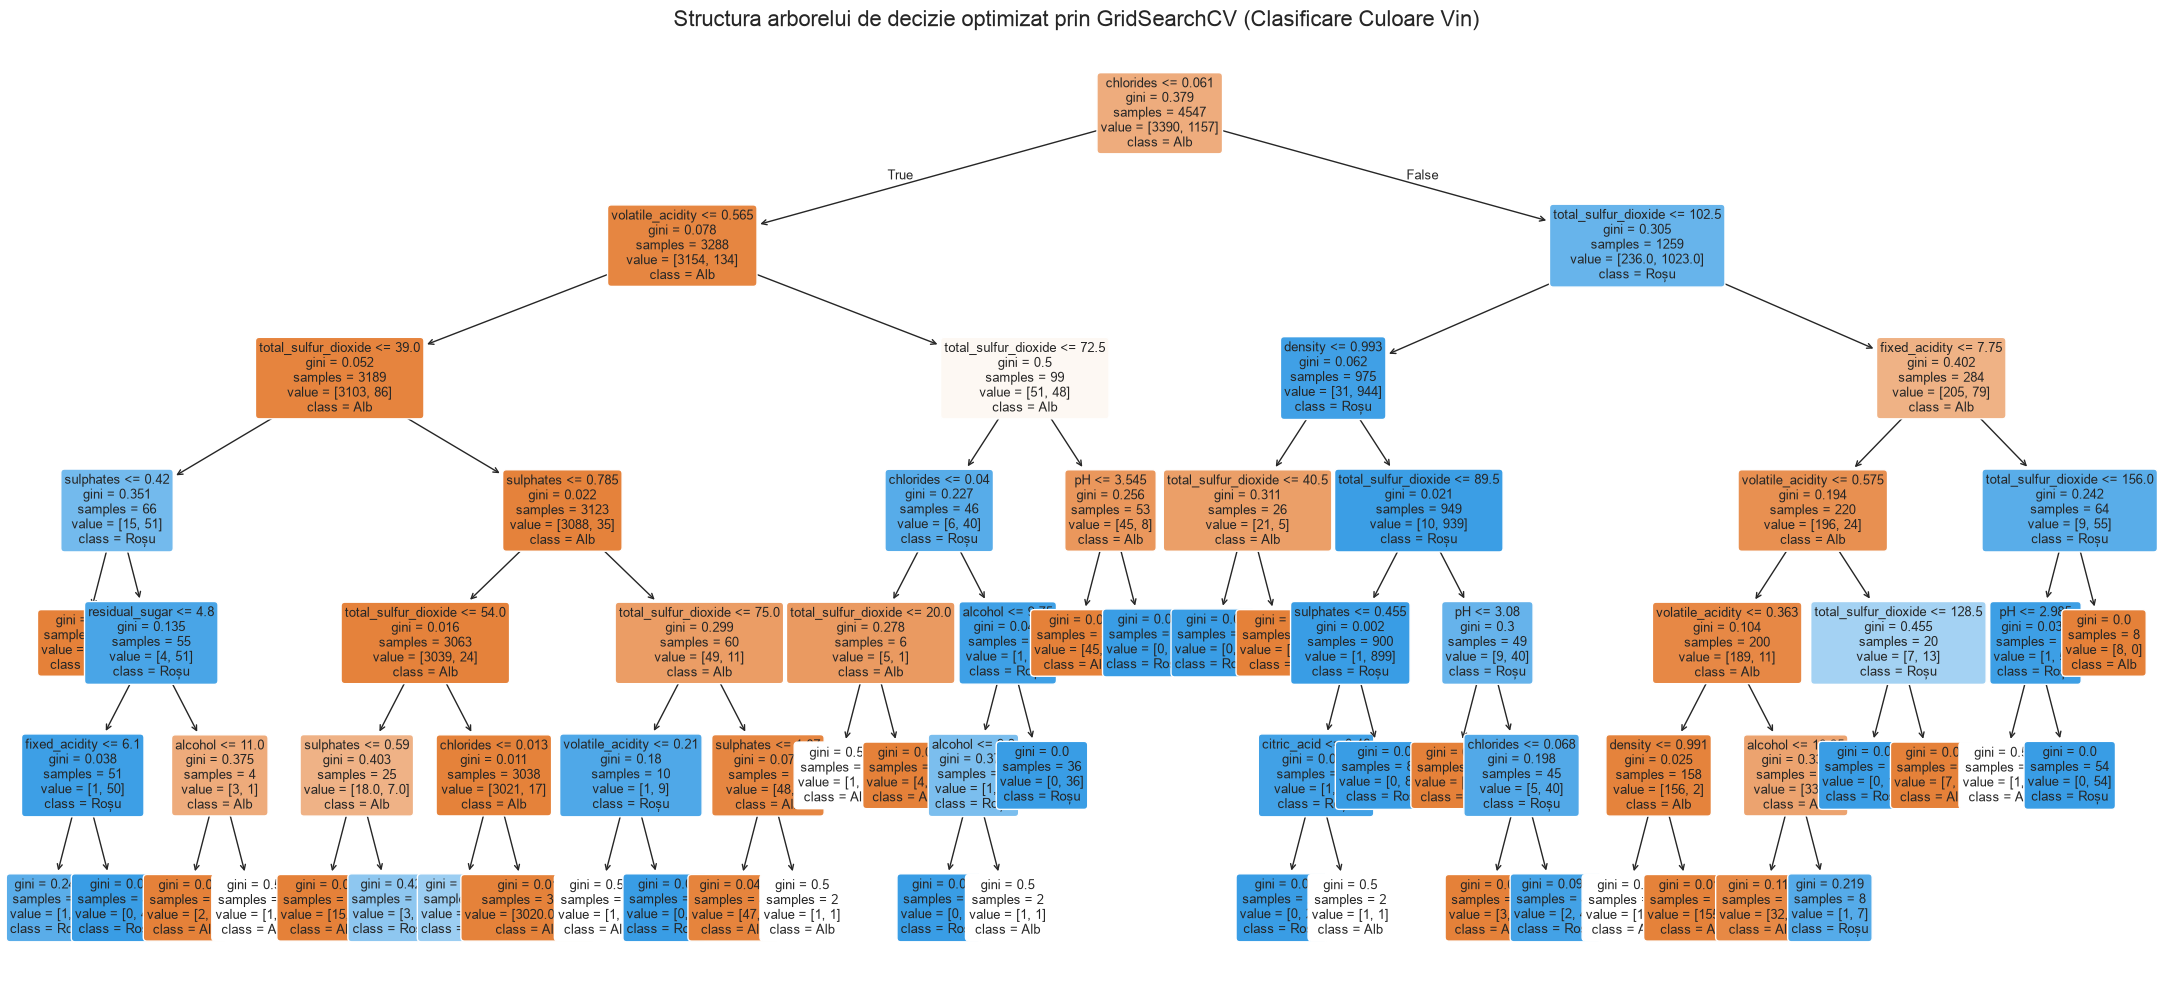

In [7]:
# Incercam randarea cu PyDotPlus / Graphviz daca sunt disponibile
try:
    import pydotplus
    dot_data = export_graphviz(
        best_tree_clf,
        out_file=None,
        feature_names=feature_cols,
        class_names=['Alb', 'Roșu'],
        filled=True,
        rounded=True
    )
    graph = pydotplus.graph_from_dot_data(dot_data)
    from IPython.display import Image
    display(Image(graph.create_png()))
    print("Vizualizare realizată cu succes prin PyDotPlus.")
except Exception as e:
    print(f"PyDotPlus/Graphviz nu este disponibil în mediul local: {e}")
    print("Vom afișa structura arborelui optimizat utilizând funcția nativă 'plot_tree' din scikit-learn:")

# Vizualizarea structurii arborelui optimizat din Intrebarea 4 cu plot_tree
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(
    best_tree_clf,
    feature_names=feature_cols,
    class_names=['Alb', 'Roșu'],
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax
)
ax.set_title("Structura arborelui de decizie optimizat prin GridSearchCV (Clasificare Culoare Vin)", fontsize=16, pad=15)
plt.tight_layout()
plt.show()

## Concluzii Laboratorul 8:
1. **Stratificarea**: Împărțirea datelor cu `StratifiedShuffleSplit` în funcție de `quality` asigură menținerea proporției exacte a fiecărei categorii atât în setul de antrenare, cât și în cel de testare, evitând sub-reprezentarea claselor rare (calități 3 sau 9).
2. **Controlul Overfitting-ului**: Un arbore neconstrâns memorează datele de antrenare (eroare 0%), dar creează un model uriaș. Prin optimizarea cu `GridSearchCV` (`max_depth`, `min_samples_leaf`, `max_features`), numărul de noduri a fost redus dramatic, menținând în același timp o capacitate excelentă de generalizare.
3. **Arbori de Regresie**: Pentru variabile continue (`residual_sugar`), arborele determină praguri care minimizează dispersia (MSE) în fiecare frunză, oferind o aproximare în trepte a funcției continue a zahărului rezidual.
4. **Interpretabilitate**: Unul dintre marile avantaje ale arborilor de decizie este transparența deciziilor, permițând vizualizarea și explicarea facilă a fiecărui pas logic prin reguli de tip `if-then`.